# Colab Intro

## Suma ciagu geometrycznego

Ciag geometryczny ma postac:

$$
a, ar, ar^2, \ldots, ar^{n-1}
$$

Suma pierwszych $n$ wyrazow wynosi:

$$
S_n = a + ar + ar^2 + \cdots + ar^{n-1}
= \begin{cases}
a\,\dfrac{1-r^n}{1-r}, & r \ne 1, \\
na, & r = 1.
\end{cases}
$$

Przyklad: dla $a=2$, $r=3$ i $n=4$ otrzymujemy $2+6+18+54=80$.

In [ ]:
wynik_dodawania = 2 + 2
print(wynik_dodawania)

4


In [ ]:
import math

wynik_pi_do_pi = math.pi ** math.pi
print(wynik_pi_do_pi)

36.4621596072079


In [ ]:
suma_kwadratow = sum(liczba**2 for liczba in range(1, 101))
print(suma_kwadratow)

338350


In [ ]:
from pathlib import Path

katalog_wynikowy = Path.cwd()
plik_wyniku = katalog_wynikowy / "colab_wynik.txt"
plik_wyniku.write_text(f"Suma kwadratow liczb od 1 do 100: {suma_kwadratow}\n", encoding="utf-8")
print(f"Zapisano plik: {plik_wyniku.resolve()}")

Zapisano plik: /content/colab_wynik.txt


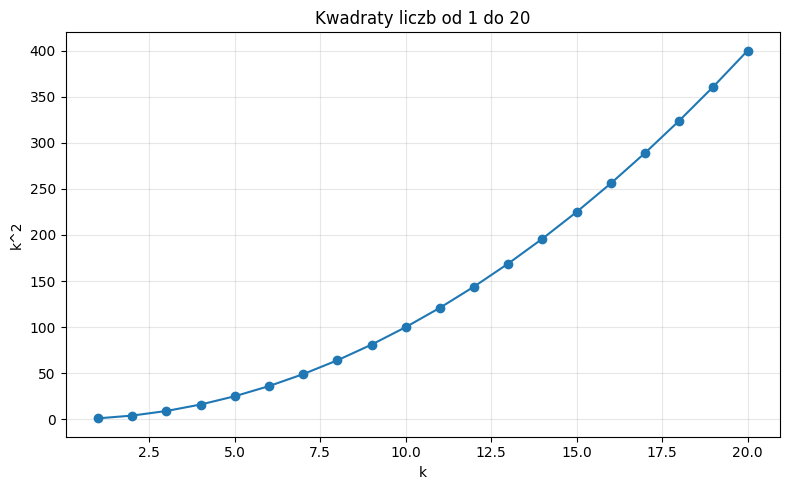

Zapisano wykres: /content/wykres.png


In [ ]:
import matplotlib.pyplot as plt

wartosci_k = range(1, 21)
kwadraty_k = [k**2 for k in wartosci_k]

figura_kwadratow, os_kwadratow = plt.subplots(figsize=(8, 5))
os_kwadratow.plot(wartosci_k, kwadraty_k, marker="o")
os_kwadratow.set(title="Kwadraty liczb od 1 do 20", xlabel="k", ylabel="k^2")
os_kwadratow.grid(True, alpha=0.3)
figura_kwadratow.tight_layout()
plt.show()

plik_wykresu = Path.cwd() / "wykres.png"
figura_kwadratow.savefig(plik_wykresu, dpi=150, bbox_inches="tight")
print(f"Zapisano wykres: {plik_wykresu.resolve()}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import Video, display

fps = 30
czas = np.linspace(0, 4, 4 * fps)
dlugosc = 1.0
grawitacja = 9.81
kat = 0.8 * np.cos(np.sqrt(grawitacja / dlugosc) * czas)

figura_wahadla, os_wahadla = plt.subplots(figsize=(5, 5))
os_wahadla.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal")
os_wahadla.axis("off")
linka, = os_wahadla.plot([], [], "o-", lw=3, color="darkslateblue", markersize=12)


def aktualizuj_wahadlo(indeks):
    x = dlugosc * np.sin(kat[indeks])
    y = -dlugosc * np.cos(kat[indeks])
    linka.set_data([0, x], [0, y])
    return (linka,)


animacja_wahadla = FuncAnimation(figura_wahadla, aktualizuj_wahadlo, frames=len(czas), interval=1000 / fps, blit=True)
plik_wideo = Path.cwd() / "video.mp4"
animacja_wahadla.save(plik_wideo, writer=FFMpegWriter(fps=fps, codec="libx264", extra_args=["-pix_fmt", "yuv420p"]))
plt.close(figura_wahadla)
print(f"Zapisano wideo: {plik_wideo.resolve()}")
display(Video(str(plik_wideo), embed=True))

Zapisano wideo: /content/video.mp4


In [ ]:
import shutil
import subprocess
from pathlib import Path

plik_wideo = Path.cwd() / "video.mp4"
plik_gif = Path.cwd() / "video.gif"
ffmpeg = shutil.which("ffmpeg")

if not plik_wideo.is_file():
    raise FileNotFoundError(f"Nie znaleziono {plik_wideo.resolve()}. Uruchom najpierw komorke tworzaca video.mp4.")
if ffmpeg is None:
    raise RuntimeError("Nie znaleziono ffmpeg. W Google Colab uruchom: !apt-get -y install ffmpeg")

subprocess.run(
    [ffmpeg, "-y", "-i", str(plik_wideo), "-vf", "fps=15,scale=480:-1:flags=lanczos", "-loop", "0", str(plik_gif)],
    check=True,
    capture_output=True,
    text=True,
)
print(f"Zapisano animowany GIF: {plik_gif.resolve()}")

Zapisano animowany GIF: /content/video.gif


Zapisano krzywa 3D: /content/parametric_curve.png


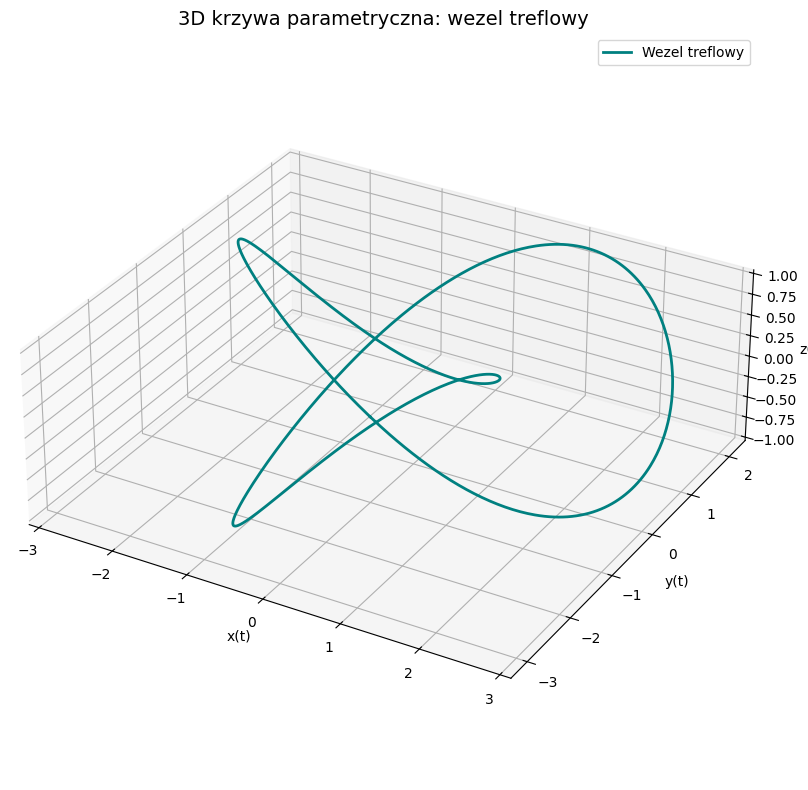

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Parametric equations for a trefoil knot
t_3d = np.linspace(0, 2 * np.pi, 1000)
x_3d = np.sin(t_3d) + 2 * np.sin(2 * t_3d)
y_3d = np.cos(t_3d) - 2 * np.cos(2 * t_3d)
z_3d = -np.sin(3 * t_3d)

figura_3d = plt.figure(figsize=(8, 8))
os_3d = figura_3d.add_subplot(111, projection="3d")
os_3d.plot(x_3d, y_3d, z_3d, label="Wezel treflowy", color="teal", linewidth=2)
os_3d.set_title("3D krzywa parametryczna: wezel treflowy", fontsize=14)
os_3d.set_xlabel("x(t)")
os_3d.set_ylabel("y(t)")
os_3d.set_zlabel("z(t)")
os_3d.set_box_aspect((np.ptp(x_3d), np.ptp(y_3d), np.ptp(z_3d)))
os_3d.legend()
figura_3d.tight_layout()

plik_krzywej_3d = Path.cwd() / "parametric_curve.png"
figura_3d.savefig(plik_krzywej_3d, dpi=150, bbox_inches="tight")
print(f"Zapisano krzywa 3D: {plik_krzywej_3d.resolve()}")
plt.show()